# Portion 7B — Confirmatory statistics: seeds, foundation baselines, temporal mechanism, forecasting regimes
**Inputs:** Portions 1–5 and **Portion 7A**. **Output:** `portion7_outputs/` (main figures 6–8, supplementary figures, tables T10–T13, text).
**CPU is fine** (≈ 10–20 min; probe fits run in parallel on all CPU cores). Nothing from earlier portions is modified.

| Section | Question | Main output |
|---|---|---|
| 4 Probes × seeds | do the Portion 3 probe results hold for every pretraining seed? (seed 0 must reproduce Portion 3 exactly) | `probes_all_seeds.csv`, T10 |
| 5 Label efficiency × seeds | same for the label-efficiency curves (seed 0 must reproduce Portion 5) | `label_efficiency_all_seeds.csv` |
| 6 Confirmatory claims | pre-specified comparisons, fold-level statistics on seed-averaged values + how many seeds agree | `claims_confirmatory.csv`, T11, **Figure 6** |
| 7 Temporal mechanism | which frames, order and motion the temporal encoders use (Portion 7A tests) | **Figure 7** |
| 8 Forecasting regimes | why forecasting lost to persistence: assembling vs non-assembling movies; a causal growth gate (*exploratory*) | T12, **Figure 8** |
| 6b New best? | does B6 or a foundation model beat the best Portion 3–6 encoder on any probe? | `new_vs_previous_best.csv`, T14 |
| 9 Nuisance & acquisition | can the embeddings tell movies apart on identical lattices? do probes transfer 200 px → 400 px sessions? | T13, Fig S7-1/2 |

**Decision rule (unchanged from Portion 6):** SUPPORTED = better on average **and** in ≥ 80 % of held-out movies (4 of 5);
NOT SUPPORTED = not better on average; otherwise INCONCLUSIVE. With 5 movies the smallest exact two-sided p is 0.0625.

In [1]:
# ---- 0. Mount Google Drive -------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using local paths.')

Mounted at /content/drive


In [2]:
# ---- 1. Imports & journal style ------------------------------------------------------------------------------
import os, json, glob, itertools, hashlib, time, warnings, logging, zipfile
from datetime import datetime
import numpy as np
import pandas as pd
from scipy.stats import t as t_dist
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold
from joblib import Parallel, delayed
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display
warnings.filterwarnings('ignore'); logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
os.environ['PYTHONWARNINGS'] = 'ignore'          # also silences the parallel worker processes
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
MM = 1 / 25.4; W1, W15, W2 = 89 * MM, 120 * MM, 183 * MM
_avail = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'] if f in _avail), 'DejaVu Sans')
plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': [FONT], 'font.size': 7, 'axes.titlesize': 7,
                     'axes.labelsize': 7, 'xtick.labelsize': 6.3, 'ytick.labelsize': 6.3, 'legend.fontsize': 6,
                     'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.major.size': 2.5,
                     'ytick.major.size': 2.5, 'lines.linewidth': 1.1, 'lines.markersize': 3.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False, 'legend.frameon': False, 'figure.dpi': 150,
                     'savefig.dpi': 600, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.titlelocation': 'left'})
def panel(ax, s, x=-0.16, y=1.03):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='left')
NJ = max(1, min(8, os.cpu_count() or 1))
print('numpy', np.__version__, '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__, '| font', FONT, '| CPU workers', NJ)

numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | font Liberation Sans | CPU workers 2


In [3]:
# ---- 2. Configuration and inputs -------------------------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/Koushik-experiment/'
DATA_DIR = os.environ.get('HSAFM_DATA_DIR', DATA_DIR)          # (local-testing override; ignore in Colab)
P = {i: os.path.join(DATA_DIR, f'portion{i}_outputs') for i in (1, 2, 3, 5, 7)}
P[4] = os.path.join(DATA_DIR, 'portion4_v2_outputs')
OUT = P[7]; MAINF, SUPF, TAB, TXT = [os.path.join(OUT, d) for d in ('main_figures', 'supplementary_figures', 'tables', 'text')]
for d in [MAINF, SUPF, TAB, TXT]:
    os.makedirs(d, exist_ok=True)
need = {1: ['frames_all.csv', 'splits.json'], 2: ['targets_per_frame.csv', 'repeatability_trace_retrace.csv'],
        3: ['dataset_index.csv', 'dataset_5nm_f16.npy', 'probe_results_per_fold.csv', 'run_config_portion3.json'],
        4: ['metrics_all_v2.csv', 'run_config_portion4_v2.json'], 5: ['label_efficiency.csv', 'run_config_portion5.json'],
        7: ['checks_portion7A.csv', 'run_config_portion7A.json', 'temporal_tests_per_clip.csv']}
missing = [os.path.join(P[k], f) for k, fs in need.items() for f in fs if not os.path.exists(os.path.join(P[k], f))]
assert not missing, 'Run Portions 1-5 and Portion 7A first. Missing:\n' + '\n'.join(missing)
cfg7a = json.load(open(os.path.join(P[7], 'run_config_portion7A.json'))); p3cfg = json.load(open(os.path.join(P[3], 'run_config_portion3.json')))
p4cfg = json.load(open(os.path.join(P[4], 'run_config_portion4_v2.json')))['config']; p5cfg = json.load(open(os.path.join(P[5], 'run_config_portion5.json')))['config']
QUICK = bool(p3cfg.get('QUICK', False))
SEEDS = [int(s) for s in cfg7a['seeds']]; LOCO_ = list(cfg7a['loco'])
LABEL_FRACTIONS = tuple(p5cfg.get('LABEL_FRACTIONS', (0.02, 0.05, 0.10, 0.25, 0.50, 1.00))); LABEL_REPEATS = int(p5cfg.get('LABEL_REPEATS', 5))
BLOCK_S, SEED = float(p5cfg.get('BLOCK_S', 30.0)), int(p5cfg.get('SEED', 0))
SUPPORT_MIN_FRAC = 0.8
FOUND_NAMES = ['B1-IN', 'B1-DINO', 'B6-init']                         # frozen encoders (no training on HS-AFM)
SSL = ['B0', 'B2', 'B3', 'B4', 'B5']; FOUND = [k for k in FOUND_NAMES if os.path.exists(os.path.join(P[7], 'embeddings_foundation', f'{k}.npz'))]
B6_INIT = cfg7a.get('b6', {}).get('init', 'B1-DINO')                 # the frozen foundation model B6 started from
HAS_B6 = all(os.path.exists(os.path.join(P[7], 'embeddings_seeds', s, 'B6__s0.npz')) for s in cfg7a['loco'])
SINGLE = FOUND + (['B6'] if HAS_B6 else [])                             # encoders with one run per fold (no pretraining seeds)
ENCODERS = ['B0'] + [f for f in FOUND if f != 'B6-init'] + ['B2', 'B3', 'B4', 'B5'] + (['B6-init'] if 'B6-init' in FOUND else []) + (['B6'] if HAS_B6 else [])
PREVIOUS = ['B0', 'B2', 'B3', 'B4', 'B5']                               # the encoders of Portions 3-6
VCOL = {'B0': '#9a9a9a', 'B1-IN': '#7d5a3c', 'B1-DINO': '#b08bd6', 'B6-init': '#e7a3c6', 'B2': '#1baf7a', 'B3': '#eb6834', 'B4': '#2a78d6',
        'B5': '#eda100', 'B6': '#c2307a'}
VNAME = {'B0': 'B0 random init', 'B1-IN': 'B1 ImageNet ViT-S', 'B1-DINO': 'B1 DINOv2 ViT-S', 'B2': 'B2 frame MAE',
         'B3': 'B3 temporal MAE', 'B4': 'B4 temporal MAE + InfoNCE', 'B5': 'B5 shuffled time',
         'B6': f"B6 = B4 from {dict({'B1-DINO': 'DINOv2', 'B1-IN': 'ImageNet'}).get(B6_INIT, B6_INIT)} weights",
         'B6-init': 'B6 before training (frozen)'}
MCOL = {'persistence': '#b5b5b5', 'linear': '#8f8f8f', 'kinetic': '#5c5c5c', 'MLP-desc': '#3a3a3a', 'B4': '#6250d6',
        'B4+phys': '#2a78d6', 'nested-selected': '#0b0b0b'}
conc_order = lambda c: float(str(c).replace('nM', ''))
splits = json.load(open(os.path.join(P[1], 'splits.json')))['splits']
LOCO = [s for s in LOCO_ if s in splits]
print(f'Portion-3 QUICK={QUICK} | seeds {SEEDS} | encoders {ENCODERS} | LOCO {LOCO} | label repeats {LABEL_REPEATS}')
if not {'B1-IN', 'B1-DINO'} <= set(FOUND):
    print('NOTE: a foundation baseline is missing (Portion 7A could not download it); its comparisons are reported as not available.')
def save(fig, name, folder=MAINF):
    fig.savefig(os.path.join(folder, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(folder, f'{name}.png'), bbox_inches='tight', dpi=600)
    try:
        fig.savefig(os.path.join(folder, f'{name}.tiff'), bbox_inches='tight', dpi=600, pil_kwargs={'compression': 'tiff_lzw'})
    except Exception as e:
        print('TIFF export skipped:', e)
    plt.show()

Portion-3 QUICK=False | seeds [0, 1, 2] | encoders ['B0', 'B1-IN', 'B1-DINO', 'B2', 'B3', 'B4', 'B5', 'B6-init', 'B6'] | LOCO ['LOCO_2nM', 'LOCO_4nM', 'LOCO_6nM', 'LOCO_8nM', 'LOCO_10nM'] | label repeats 5


In [4]:
# ---- 3. Labels (Portion 3 definitions), embedding registry and shared statistics ---------------------------------------------------
idx = pd.read_csv(os.path.join(P[3], 'dataset_index.csv'))
frames = pd.read_csv(os.path.join(P[1], 'frames_all.csv')); tg = pd.read_csv(os.path.join(P[2], 'targets_per_frame.csv')).set_index('frame_id')
lab = idx[['frame_id', 'conc', 't_rel_s']].join(tg[['coverage', 'fft_peak_ratio', 'fft_psi6', 'density_um2', 'regime', 'lattice_valid',
                                                    'count_valid', 'contrast_ok']], on='frame_id')
streak = idx.frame_id.map(frames.set_index('frame_id').warn_streaks).fillna(False).astype(bool).values
lab.loc[streak, ['coverage', 'fft_peak_ratio', 'fft_psi6', 'density_um2']] = np.nan
lab.loc[streak, 'regime'] = 'excluded'
fut = []
for c, g in lab.groupby('conc'):
    tt, cv = g.t_rel_s.values, g.coverage.values
    j = np.searchsorted(tt, tt + 30.0).clip(0, len(tt) - 1); ok = np.abs(tt[j] - (tt + 30.0)) <= 5.0
    fut.append(pd.Series(np.where(ok, cv[j] - cv, np.nan), index=g.index))
lab['dcov_30s'] = pd.concat(fut)
lab['nx'] = idx.frame_id.map(frames.set_index('frame_id').nx).values
CONCS = sorted(lab.conc.unique(), key=conc_order)
CCOL = {c: plt.get_cmap('Blues')(0.38 + 0.54 * i / max(1, len(CONCS) - 1)) for i, c in enumerate(CONCS)}
PROBES = {   # Portion 3 (name: column, transform, validity column, kind)
    'coverage':          ('coverage', None, 'contrast_ok', 'reg'),
    'lattice sharpness': ('fft_peak_ratio', np.log, None, 'reg'),
    'ψ6 (dense)':        ('fft_psi6', None, 'lattice_valid', 'reg'),
    'density (sparse)':  ('density_um2', np.log1p, 'count_valid', 'reg'),
    'Δcoverage +30 s':   ('dcov_30s', None, None, 'reg'),
    'regime':            ('regime', None, 'contrast_ok', 'cls'),
}
PROBES5 = {'coverage': ('coverage', None, 'contrast_ok'), 'density (sparse)': ('density_um2', np.log1p, 'count_valid'),
           'lattice sharpness': ('fft_peak_ratio', np.log, None)}

def emb_file(split, v, sd):
    if v in FOUND_NAMES: return os.path.join(P[7], 'embeddings_foundation', f'{v}.npz')
    if v == 'B6': return os.path.join(P[7], 'embeddings_seeds', split, 'B6__s0.npz')
    if sd == 0: return os.path.join(P[3], 'embeddings', split, f'{v}.npz')
    if v == 'B0': return os.path.join(P[7], 'embeddings_seeds', '_B0', f'B0__s{sd}.npz')
    return os.path.join(P[7], 'embeddings_seeds', split, f'{v}__s{sd}.npz')
def load_Z(split, v, sd):
    d = np.load(emb_file(split, v, sd), allow_pickle=True)
    assert len(d['Z']) == len(idx), f'{emb_file(split, v, sd)}: rows differ from dataset_index.csv'
    tc = set(str(x) for x in d['train_concs']) if 'train_concs' in d.files else set()
    assert tc.isdisjoint(splits[split]['test']), f'LEAKAGE: {v} seed {sd} for {split} saw a test movie'
    return d['Z'].astype(np.float32)
ENC_SEEDS = [(v, sd) for v in SSL for sd in SEEDS if all(os.path.exists(emb_file(s, v, sd)) for s in LOCO)] + [(v, 0) for v in SINGLE]
missing_enc = [(v, sd) for v in SSL for sd in SEEDS if (v, sd) not in ENC_SEEDS]
if missing_enc: print('embeddings not found (skipped):', missing_enc)
print(f'{len(ENC_SEEDS)} encoder x seed combinations x {len(LOCO)} folds')

# ---- ridge exactly as Portion 3 (probes) and Portion 5 (label efficiency) ----
def ridge_path(A, y, alphas):
    Ac = A - A.mean(0); yc = y - y.mean()
    ev, V = np.linalg.eigh(Ac.T @ Ac); r = V.T @ (Ac.T @ yc)
    return [(V @ (r / (ev + al)), y.mean(), A.mean(0)) for al in alphas]
def ridge_fit_predict(Xtr, ytr, Xte, groups, alphas=(1, 10, 100, 1000, 10000)):
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    A, B = (Xtr - mu) / sd, (Xte - mu) / sd
    err = np.zeros(len(alphas)); ug = np.unique(groups)
    if len(ug) >= 2:
        for gg in ug:
            tr = groups != gg
            for k, (w, b, m) in enumerate(ridge_path(A[tr], ytr[tr], alphas)):
                err[k] += np.mean(np.abs((A[~tr] - m) @ w + b - ytr[~tr]))
    w, b, m = ridge_path(A, ytr, [alphas[int(np.argmin(err))]])[0]
    return (B - m) @ w + b
def ridge_fit(A, y, alpha):
    m = A.mean(0); Ac = A - m; yc = y - y.mean(); n, d = Ac.shape
    w = Ac.T @ np.linalg.solve(Ac @ Ac.T + alpha * np.eye(n), yc) if n < d else np.linalg.solve(Ac.T @ Ac + alpha * np.eye(d), Ac.T @ yc)
    return w, y.mean(), m
ALPHAS = (1, 10, 100, 1000, 10000)
def choose_alpha(A, y, groups):
    err = np.zeros(len(ALPHAS))
    for gg in np.unique(groups):
        tr = groups != gg
        if tr.sum() < 10 or (~tr).sum() < 3: continue
        Ac = A[tr] - A[tr].mean(0); yc = y[tr] - y[tr].mean(); ev, V = np.linalg.eigh(Ac.T @ Ac); r = V.T @ (Ac.T @ yc)
        for k, al in enumerate(ALPHAS):
            w = V @ (r / (ev + al)); err[k] += np.mean(np.abs((A[~tr] - A[tr].mean(0)) @ w + y[tr].mean() - y[~tr]))
    return ALPHAS[int(np.argmin(err))]
def label_vec(name):
    col, fn, vm = PROBES5[name]; y = lab[col].values.astype(float); ok = np.isfinite(y)
    if vm is not None: ok &= lab[vm].astype(bool).values
    if fn is not None: y = np.where(ok, fn(np.where(ok, y, 1.0)), np.nan)
    return y, ok

# ---- statistics (Portion 6) ----
def signflip_p(d):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    if n == 0: return np.nan
    signs = np.array(list(itertools.product([-1, 1], repeat=n)))
    return float(np.mean(np.abs((signs * d).mean(1)) >= abs(d.mean()) - 1e-12))
def bh(p):
    p = np.asarray(p, float); n = np.sum(np.isfinite(p)); o = np.argsort(np.where(np.isfinite(p), p, np.inf))
    q = np.full_like(p, np.nan); prev = 1.0
    for rank, i in reversed(list(enumerate(o[:n], start=1))):
        prev = min(prev, p[i] * n / rank); q[i] = prev
    return q
def paired_row(d):
    """d = per-movie improvement (> 0 = reference better)."""
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    if n < 2: return dict(n=n, improvement=np.nan, CI95_low=np.nan, CI95_high=np.nan, cohens_dz=np.nan, won=0, p=np.nan)
    sd = d.std(ddof=1); ci = t_dist.ppf(0.975, n - 1) * sd / np.sqrt(n)
    return dict(n=n, improvement=d.mean(), CI95_low=d.mean() - ci, CI95_high=d.mean() + ci, cohens_dz=d.mean() / sd if sd > 0 else np.nan,
                won=int((d > 0).sum()), p=signflip_p(d))
def verdict(r):
    if not np.isfinite(r['improvement']): return 'NOT AVAILABLE'
    if r['improvement'] <= 0: return 'NOT SUPPORTED'
    return 'SUPPORTED' if r['won'] >= int(np.ceil(SUPPORT_MIN_FRAC * r['n'])) else 'INCONCLUSIVE'
def _quiet(fn, *a):
    import warnings as _w
    with _w.catch_warnings():
        _w.simplefilter('ignore'); return fn(*a)
def pmap(fn, tasks):
    """run fn(*task) for every task on all CPU cores (falls back to one core if parallel workers are unavailable)."""
    if NJ > 1 and len(tasks) > 1:
        try:
            return Parallel(n_jobs=NJ, backend='loky')(delayed(_quiet)(fn, *t) for t in tasks)
        except Exception as e:
            print('parallel run unavailable -> one core:', type(e).__name__, str(e)[:120])
    return [_quiet(fn, *t) for t in tasks]

embeddings not found (skipped): [('B2', 1), ('B2', 2), ('B3', 2), ('B4', 2), ('B5', 2)]
14 encoder x seed combinations x 5 folds


In [5]:
# ---- 4. Linear probes for every encoder x seed (seed 0 must reproduce Portion 3) -------------------------------------------------------
def probe_task(s, v, sd):
    Z = load_Z(s, v, sd); tr_c, te_c = splits[s]['train'], splits[s]['test']; rows = []
    for pname, (col, fn, vm, kind) in PROBES.items():
        ok = lab[col].notna().values
        if vm is not None: ok &= lab[vm].astype(bool).values
        if kind == 'cls': ok &= lab[col].isin(['sparse', 'transition', 'dense']).values
        tr = ok & lab.conc.isin(tr_c).values; te = ok & lab.conc.isin(te_c).values
        if tr.sum() < 20 or te.sum() < 5: continue
        if kind == 'reg':
            y = lab[col].values.astype(float); y = fn(y) if fn is not None else y
            p = ridge_fit_predict(Z[tr], y[tr], Z[te], lab.conc.values[tr])
            rows.append(dict(split=s, test=te_c[0], variant=v, seed=sd, probe=pname, metric='MAE', value=float(np.mean(np.abs(p - y[te]))), n=int(te.sum())))
        else:
            yc = lab[col].values; mu, sdv = Z[tr].mean(0), Z[tr].std(0) + 1e-6
            clf = LogisticRegression(max_iter=2000, class_weight='balanced', C=0.1).fit((Z[tr] - mu) / sdv, yc[tr])
            rows.append(dict(split=s, test=te_c[0], variant=v, seed=sd, probe=pname, metric='balanced acc.',
                             value=float(balanced_accuracy_score(yc[te], clf.predict((Z[te] - mu) / sdv))), n=int(te.sum())))
    return rows
t0 = time.time()
PR = pd.DataFrame([r for rows in pmap(probe_task, [(s, v, sd) for s in LOCO for v, sd in ENC_SEEDS]) for r in rows])
PR.to_csv(os.path.join(OUT, 'probes_all_seeds.csv'), index=False)
print(f'{len(PR)} probe results in {time.time() - t0:.0f}s')
p3pr = pd.read_csv(os.path.join(P[3], 'probe_results_per_fold.csv'))
cmp_ = PR[PR.seed == 0].merge(p3pr, on=['split', 'variant', 'probe', 'metric'], suffixes=('', '_p3'))
dif = (cmp_.value - cmp_.value_p3).abs()
REPRO_P3 = dict(n=len(cmp_), max_abs_diff_MAE=float(dif[cmp_.metric == 'MAE'].max()) if (cmp_.metric == 'MAE').any() else np.nan,
                max_abs_diff_acc=float(dif[cmp_.metric != 'MAE'].max()) if (cmp_.metric != 'MAE').any() else np.nan)
REPRO_P3['ok'] = bool(len(cmp_) > 0 and REPRO_P3['max_abs_diff_MAE'] < 1e-4 and (not np.isfinite(REPRO_P3['max_abs_diff_acc']) or REPRO_P3['max_abs_diff_acc'] < 0.02))
print('seed 0 reproduces Portion 3 probes:', REPRO_P3)
FOLD = PR.groupby(['probe', 'metric', 'variant', 'split']).value.agg(['mean', 'std', 'count']).reset_index()   # seed-mean per fold
SUMM = FOLD.groupby(['probe', 'metric', 'variant']).agg(mean=('mean', 'mean'), fold_sd=('mean', 'std'), seed_sd=('std', 'mean'),
                                                         seeds=('count', 'max')).reset_index()
display(SUMM.pivot_table(index='variant', columns='probe', values='mean').reindex(ENCODERS).round(4))

406 probe results in 497s
seed 0 reproduces Portion 3 probes: {'n': 145, 'max_abs_diff_MAE': 0.0004578164370341309, 'max_abs_diff_acc': 0.0043290043290044045, 'ok': False}


probe,coverage,density (sparse),lattice sharpness,regime,Δcoverage +30 s,ψ6 (dense)
variant,,,,,,
B0,0.1196,0.1578,0.4001,0.9073,0.0274,0.1481
B1-IN,0.0422,0.1683,0.3568,0.9438,0.0273,0.1389
B1-DINO,0.0243,0.1479,0.3824,0.9481,0.0249,0.1551
B2,0.0799,0.2495,0.4057,0.9492,0.0325,0.1434
B3,0.0420,0.1889,0.4122,0.9229,0.0322,0.1548
B4,0.0433,0.2108,0.3965,0.9538,0.0362,0.1503
B5,0.0335,0.2232,0.3928,0.9375,0.0382,0.1542
B6-init,0.0796,0.2098,0.3632,0.8561,0.0404,0.1480
B6,0.0845,0.2483,0.4022,0.9184,0.0343,0.1483


In [6]:
# ---- 5. Label efficiency for every encoder x seed (seed 0 must reproduce Portion 5) -------------------------------------------------------
block_id = (lab.t_rel_s.values // BLOCK_S).astype(int)
def le_task(s, v, sd):
    Z = load_Z(s, v, sd); tr_c, te_c = splits[s]['train'], splits[s]['test']; rows = []
    for pn in PROBES5:
        y, ok = label_vec(pn)
        tr = ok & lab.conc.isin(tr_c).values; te = ok & lab.conc.isin(te_c).values
        if tr.sum() < 30 or te.sum() < 5: continue
        mu, sdv = Z[tr].mean(0), Z[tr].std(0) + 1e-6; A = (Z - mu) / sdv
        alpha = choose_alpha(A[tr], y[tr], lab.conc.values[tr])
        for f in LABEL_FRACTIONS:
            for rep in range(LABEL_REPEATS if f < 1 else 1):
                rng = np.random.default_rng(SEED + 7919 * rep + int(f * 1000))
                keep = np.zeros(len(lab), bool)
                for c in tr_c:
                    mc = tr & (lab.conc.values == c); blocks = np.unique(block_id[mc])
                    if len(blocks) == 0: continue
                    keep |= mc & np.isin(block_id, rng.choice(blocks, max(1, int(round(f * len(blocks)))), replace=False))
                if keep.sum() < 5: continue
                w, b, m = ridge_fit(A[keep], y[keep], alpha)
                rows.append(dict(split=s, test=te_c[0], variant=v, seed=sd, probe=pn, fraction=f, repeat=rep, n_labels=int(keep.sum()),
                                 MAE=float(np.mean(np.abs((A[te] - m) @ w + b - y[te])))))
    return rows
t0 = time.time()
LE = pd.DataFrame([r for rows in pmap(le_task, [(s, v, sd) for s in LOCO for v, sd in ENC_SEEDS]) for r in rows])
LE.to_csv(os.path.join(OUT, 'label_efficiency_all_seeds.csv'), index=False)
print(f'{len(LE)} label-efficiency fits in {time.time() - t0:.0f}s')
p5le = pd.read_csv(os.path.join(P[5], 'label_efficiency.csv'))
cm5 = LE[LE.seed == 0].merge(p5le, on=['split', 'variant', 'probe', 'fraction', 'repeat'], suffixes=('', '_p5'))
REPRO_P5 = dict(n=len(cm5), max_abs_diff=float((cm5.MAE - cm5.MAE_p5).abs().max()) if len(cm5) else np.nan)
REPRO_P5['ok'] = bool(len(cm5) > 0 and REPRO_P5['max_abs_diff'] < 1e-4)
print('seed 0 reproduces Portion 5 label efficiency:', REPRO_P5)
# area under the label-efficiency curve (MAE vs log10 fraction, normalised to the fraction range; lower = better)
lf = np.log10(np.array(LABEL_FRACTIONS))
def auc(g):
    m = g.groupby('fraction').MAE.mean().reindex(LABEL_FRACTIONS).values
    return float(np.sum((m[1:] + m[:-1]) / 2 * np.diff(lf)) / (lf[-1] - lf[0])) if np.isfinite(m).all() else np.nan
LEAUC = pd.DataFrame([dict(split=s, variant=v, seed=sd, probe=pn, value=auc(g)) for (s, v, sd, pn), g in LE.groupby(['split', 'variant', 'seed', 'probe'])])

5460 label-efficiency fits in 274s
seed 0 reproduces Portion 5 label efficiency: {'n': 1950, 'max_abs_diff': 0.0026605124364145194, 'ok': False}


In [7]:
# ---- 6. Confirmatory claims: fold-level statistics on seed-averaged values + seed agreement (Table T11) -------------------------------
CLAIMS_DEF = [   # id, probe, reference (proposed), comparator, statement  -- fixed before looking at the Portion 7 numbers
    ('C1', 'coverage', 'B4', 'B0', 'Temporal SSL (B4) reads coverage better than a random encoder'),
    ('C1b', 'coverage', 'B4', 'B1-IN', 'B4 reads coverage better than frozen ImageNet ViT-S features'),
    ('C1c', 'coverage', 'B4', 'B1-DINO', 'B4 reads coverage better than frozen DINOv2 ViT-S features'),
    ('C2', 'Δcoverage +30 s', 'B4', 'B5', 'True time order helps the dynamics read-out (B4 vs shuffled-time B5)'),
    ('C3', 'coverage', 'B4', 'B3', 'Temporal InfoNCE adds to temporal MAE (B4 vs B3)'),
    ('C4', 'coverage', 'B3', 'B2', 'Temporal MAE beats single-frame MAE (B3 vs B2)'),
    ('C5', 'label-efficiency AUC: coverage', 'B4', 'B0', 'B4 needs fewer labels than a random encoder (area under the curve)'),
    ('C6', 'label-efficiency AUC: coverage', 'B4', 'B1-DINO', 'B4 needs fewer labels than DINOv2 features (area under the curve)'),
    ('C7', 'coverage', 'B6', 'B4', 'Starting from foundation weights (B6) beats training from scratch (B4)'),
    ('C8', 'coverage', 'B6', B6_INIT, f'Temporal pretraining on HS-AFM improves the frozen foundation model it started from (B6 vs {B6_INIT})'),
    ('C8b', 'coverage', 'B6', 'B6-init', 'HS-AFM training improves B6 over its own starting point (same pipeline, step 0)'),
    ('C9', 'Δcoverage +30 s', 'B6', 'B4', 'B6 improves the 30-s dynamics read-out over B4'),
    ('C10', 'label-efficiency AUC: coverage', 'B6', B6_INIT, f'B6 needs fewer labels than its frozen foundation model ({B6_INIT})'),
]
def table_for(probe):
    if probe.startswith('label-efficiency AUC: '):
        return LEAUC[LEAUC.probe == probe.split(': ', 1)[1]][['split', 'variant', 'seed', 'value']]
    return PR[(PR.probe == probe) & (PR.metric == 'MAE')][['split', 'variant', 'seed', 'value']]
def fold_values(tbl, v, seed=None):
    d = tbl[tbl.variant == v]
    if seed is not None and v not in SINGLE: d = d[d.seed == seed]
    return d.groupby('split').value.mean().reindex(LOCO)
rows = []
for cid, probe, ref, comp, text in CLAIMS_DEF:
    tbl = table_for(probe)
    r = paired_row((fold_values(tbl, comp) - fold_values(tbl, ref)).values)
    seed_ok = [verdict(paired_row((fold_values(tbl, comp, sd) - fold_values(tbl, ref, sd)).values)) for sd in SEEDS]
    n_av = sum(v_ != 'NOT AVAILABLE' for v_ in seed_ok)
    rows.append(dict(id=cid, claim=text, probe=probe, reference=ref, comparator=comp,
                     MAE_reference=float(fold_values(tbl, ref).mean()), MAE_comparator=float(fold_values(tbl, comp).mean()), **r,
                     verdict=verdict(r), seeds_supporting=f"{sum(v_ == 'SUPPORTED' for v_ in seed_ok)}/{n_av}" if n_av else 'n/a'))
CL = pd.DataFrame(rows); CL['q_BH'] = bh(CL.p.values)
CL.to_csv(os.path.join(OUT, 'claims_confirmatory.csv'), index=False)
display(CL[['id', 'claim', 'MAE_reference', 'MAE_comparator', 'improvement', 'CI95_low', 'CI95_high', 'cohens_dz', 'won', 'n', 'p', 'q_BH',
            'verdict', 'seeds_supporting']].round(4))
best = SUMM[SUMM.metric == 'MAE'].loc[lambda d: d.groupby('probe')['mean'].idxmin()][['probe', 'variant', 'mean']]
print('best encoder per probe (seed-averaged LOCO mean):'); display(best.round(4))
# does any NEW encoder beat the best encoder of Portions 3-6? (strict test: the comparator is the best of the five previous encoders)
NB = []
for pn in [p_ for p_, spec in PROBES.items() if spec[3] == 'reg']:
    tbl = PR[(PR.probe == pn) & (PR.metric == 'MAE')][['split', 'variant', 'seed', 'value']]
    prevm = {v: float(fold_values(tbl, v).mean()) for v in PREVIOUS if v in set(tbl.variant)}
    if not prevm: continue
    pb = min(prevm, key=prevm.get)
    for v in [x for x in ['B1-IN', 'B1-DINO', 'B6-init', 'B6'] if x in set(tbl.variant)]:
        r = paired_row((fold_values(tbl, pb) - fold_values(tbl, v)).values); mv = float(fold_values(tbl, v).mean())
        NB.append(dict(probe=pn, encoder=v, previous_best=pb, MAE_previous_best=prevm[pb], MAE_encoder=mv,
                       change_pct=100 * (prevm[pb] - mv) / prevm[pb], movies_better=f"{r['won']}/{r['n']}", p=r['p'], verdict=verdict(r)))
NEWBEST = pd.DataFrame(NB); NEWBEST.to_csv(os.path.join(OUT, 'new_vs_previous_best.csv'), index=False)
if len(NEWBEST):
    print('new encoders vs the best Portion 3-6 encoder per probe (change_pct > 0 = lower error):'); display(NEWBEST.round(4))

,id,claim,MAE_reference,MAE_comparator,improvement,CI95_low,CI95_high,cohens_dz,won,n,p,q_BH,verdict,seeds_supporting
0,C1,Temporal SSL (B4) reads coverage better than a...,0.0433,0.1196,0.0763,-0.0644,0.2171,0.6733,5,5,0.0625,0.1625,SUPPORTED,2/2
1,C1b,B4 reads coverage better than frozen ImageNet ...,0.0433,0.0422,-0.0011,-0.0397,0.0376,-0.0348,2,5,0.8750,0.9375,NOT SUPPORTED,0/2
2,C1c,B4 reads coverage better than frozen DINOv2 Vi...,0.0433,0.0243,-0.0190,-0.0457,0.0076,-0.8858,2,5,0.2500,0.4062,NOT SUPPORTED,0/2
3,C2,True time order helps the dynamics read-out (B...,0.0362,0.0382,0.0021,-0.0027,0.0069,0.5362,4,5,0.2500,0.4062,SUPPORTED,1/2
4,C3,Temporal InfoNCE adds to temporal MAE (B4 vs B3),0.0433,0.0420,-0.0012,-0.0264,0.0239,-0.0615,2,5,0.9375,0.9375,NOT SUPPORTED,0/2
5,C4,Temporal MAE beats single-frame MAE (B3 vs B2),0.0420,0.0799,0.0379,-0.0250,0.1007,0.7477,5,5,0.0625,0.1625,SUPPORTED,1/1
6,C5,B4 needs fewer labels than a random encoder (a...,0.1059,0.1539,0.0481,-0.0335,0.1296,0.7318,5,5,0.0625,0.1625,SUPPORTED,2/2
7,C6,B4 needs fewer labels than DINOv2 features (ar...,0.1059,0.0774,-0.0285,-0.0628,0.0058,-1.0314,1,5,0.1250,0.2708,NOT SUPPORTED,0/2
8,C7,Starting from foundation weights (B6) beats tr...,0.0845,0.0433,-0.0412,-0.1598,0.0774,-0.4313,2,5,0.6250,0.8125,NOT SUPPORTED,0/2
9,C8,Temporal pretraining on HS-AFM improves the fr...,0.0845,0.0243,-0.0602,-0.1993,0.0789,-0.5374,0,5,0.0625,0.1625,NOT SUPPORTED,0/3


best encoder per probe (seed-averaged LOCO mean):


,probe,variant,mean
1,coverage,B1-DINO,0.0243
10,density (sparse),B1-DINO,0.1479
20,lattice sharpness,B1-IN,0.3568
37,Δcoverage +30 s,B1-DINO,0.0249
47,ψ6 (dense),B1-IN,0.1389


new encoders vs the best Portion 3-6 encoder per probe (change_pct > 0 = lower error):


,probe,encoder,previous_best,MAE_previous_best,MAE_encoder,change_pct,movies_better,p,verdict
0,coverage,B1-IN,B5,0.0335,0.0422,-25.7942,3/5,0.8750,NOT SUPPORTED
1,coverage,B1-DINO,B5,0.0335,0.0243,27.6628,3/5,0.3750,INCONCLUSIVE
2,coverage,B6-init,B5,0.0335,0.0796,-137.2550,0/5,0.0625,NOT SUPPORTED
3,coverage,B6,B5,0.0335,0.0845,-151.8725,0/5,0.0625,NOT SUPPORTED
4,lattice sharpness,B1-IN,B5,0.3928,0.3568,9.1680,4/5,0.1250,SUPPORTED
5,lattice sharpness,B1-DINO,B5,0.3928,0.3824,2.6431,3/5,0.4375,INCONCLUSIVE
6,lattice sharpness,B6-init,B5,0.3928,0.3632,7.5434,5/5,0.0625,SUPPORTED
7,lattice sharpness,B6,B5,0.3928,0.4022,-2.3912,2/5,0.6250,NOT SUPPORTED
8,ψ6 (dense),B1-IN,B2,0.1434,0.1389,3.1593,3/4,0.6250,INCONCLUSIVE
9,ψ6 (dense),B1-DINO,B2,0.1434,0.1551,-8.1430,2/4,0.5000,NOT SUPPORTED


In [8]:
# ---- 7. Temporal mechanism (Portion 7A tests): statistics over folds x seeds ---------------------------------------------------------------
IMP = pd.read_csv(os.path.join(P[7], 'temporal_frame_importance.csv')); ORD = pd.read_csv(os.path.join(P[7], 'temporal_order_sensitivity.csv'))
MOT = pd.read_csv(os.path.join(P[7], 'temporal_motion_test.csv')); TV = [v for v in ['B3', 'B4', 'B5', 'B6'] if v in ORD.variant.unique()]
TFRAMES = int(IMP.frame_pos.max()) + 1 if len(IMP) else 8
temp_rows = []
for v in TV:
    o = ORD[ORD.variant == v].groupby(['split', 'perturbation']).emb_change_rel.mean().unstack('perturbation')
    mo = MOT[MOT.variant == v].groupby('split')[[c for c in ['dMAE_static', 'dMAE_shuffled', 'dMAE_reversed'] if c in MOT.columns]].mean()
    temp_rows.append(dict(variant=v, **{f'order_change_{c}': o[c].mean() for c in o.columns}, **{c: mo[c].mean() for c in mo.columns},
                          **{f'{c}_folds_positive': f'{int((mo[c] > 0).sum())}/{len(mo)}' for c in mo.columns}))
TEMPS = pd.DataFrame(temp_rows); display(TEMPS.round(4))
TEMP_STATS = []
for comp in ['B5', 'B3', 'B6']:                   # does B4 depend on order / motion more than the controls (and than B6)?
    if 'B4' not in TV or comp not in TV: continue
    for c in ['dMAE_static', 'dMAE_shuffled']:
        if c not in MOT.columns: continue
        a = MOT[MOT.variant == 'B4'].groupby('split')[c].mean(); b = MOT[MOT.variant == comp].groupby('split')[c].mean()
        TEMP_STATS.append(dict(test=f'{c}: B4 vs {comp}', **paired_row((a - b.reindex(a.index)).values)))
TEMP_STATS = pd.DataFrame(TEMP_STATS)
if len(TEMP_STATS): TEMP_STATS['verdict'] = [verdict(r) for _, r in TEMP_STATS.iterrows()]; display(TEMP_STATS.round(4))

,variant,order_change_reversed,order_change_shuffled,order_change_static,dMAE_static,dMAE_shuffled,dMAE_reversed,dMAE_static_folds_positive,dMAE_shuffled_folds_positive,dMAE_reversed_folds_positive
0,B3,0.6790,0.6966,1.0634,0.0161,-0.0017,0.0019,2/5,1/5,3/5
1,B4,0.3027,0.5889,1.4227,0.0028,-0.0020,0.0010,3/5,2/5,4/5
2,B5,0.2929,0.6315,1.5485,0.0034,-0.0016,0.0007,3/5,2/5,3/5
3,B6,0.2167,0.9200,1.9348,-0.0009,-0.0004,0.0002,2/5,2/5,3/5


,test,n,improvement,CI95_low,CI95_high,cohens_dz,won,p,verdict
0,dMAE_static: B4 vs B5,5,-0.0006,-0.0140,0.0128,-0.0524,3,1.0000,NOT SUPPORTED
1,dMAE_shuffled: B4 vs B5,5,-0.0004,-0.0036,0.0029,-0.1345,2,0.7500,NOT SUPPORTED
2,dMAE_static: B4 vs B3,5,-0.0133,-0.0735,0.0468,-0.2752,3,0.9375,NOT SUPPORTED
3,dMAE_shuffled: B4 vs B3,5,-0.0003,-0.0228,0.0221,-0.0179,3,0.8750,NOT SUPPORTED
4,dMAE_static: B4 vs B6,5,0.0037,-0.0180,0.0253,0.2110,3,0.6250,INCONCLUSIVE
5,dMAE_shuffled: B4 vs B6,5,-0.0015,-0.0095,0.0064,-0.2405,3,0.6250,NOT SUPPORTED


In [9]:
# ---- 8. Forecasting regimes (exploratory): why forecasts lost to persistence, and a causal growth gate -----------------------------------
# targets rebuilt exactly as Portion 4 v2 (verified against its saved metrics below)
HORIZONS = tuple(float(h) for h in p4cfg['HORIZONS']); ACTIVE_MAX_COV = float(p4cfg.get('ACTIVE_MAX_COV', 0.95)); PH = 30.0 if 30.0 in HORIZONS else HORIZONS[1]
SELECTED, PROPOSED = p4cfg.get('SELECTED', 'nested-selected'), p4cfg.get('PROPOSED', 'B4+phys')
A_ = idx.join(tg[['coverage', 'contrast_ok']], on='frame_id'); N = len(A_)
Ycov = np.where(A_.contrast_ok.astype(bool), A_.coverage, np.nan); Ycov[streak] = np.nan
T_ABS = A_.t_rel_s.values
YF = np.full((N, len(HORIZONS)), np.nan)
for c in CONCS:
    rr = np.where(A_.conc.values == c)[0]; tt = T_ABS[rr]
    for hi, h in enumerate(HORIZONS):
        j = np.searchsorted(tt, tt + h).clip(0, len(tt) - 1); jm = (j - 1).clip(0)
        jj = np.where(np.abs(tt[jm] - (tt + h)) < np.abs(tt[j] - (tt + h)), jm, j)
        okh = np.abs(tt[jj] - (tt + h)) <= max(3.0, 0.15 * h)
        YF[rr[okh], hi] = Ycov[rr[jj[okh]]]
rep = pd.read_csv(os.path.join(P[2], 'repeatability_trace_retrace.csv'))
NOISE = float(np.nanmean(np.abs(rep.cov_trace - rep.cov_retrace))); DELTA = 2 * NOISE        # growth threshold = 2 x measurement noise
def growth_gate(rows):
    """causal, latching gate per movie: open once the 30-s running median of coverage exceeds the movie's first-30-s median by DELTA."""
    t, th = T_ABS[rows], Ycov[rows]; meas = np.isfinite(th); g = np.zeros(len(rows), bool)
    if not meas.any(): return g
    t0 = t[meas][0]; base = np.median(th[meas & (t <= t0 + 30.0)])
    for i in range(len(rows)):
        w = meas & (t <= t[i]) & (t > t[i] - 30.0)
        g[i] = bool(w.any()) and (np.median(th[w]) - base > DELTA)
    return np.maximum.accumulate(g)
GATE = np.zeros(N, bool)
for c in CONCS:
    rr = np.where(A_.conc.values == c)[0]; GATE[rr] = growth_gate(rr)
q = lab.groupby('conc').coverage.quantile([0.05, 0.95]).unstack()
REGIME = {c: ('assembling' if (q.loc[c, 0.95] - q.loc[c, 0.05]) > 0.30 else 'non-assembling') for c in CONCS}
print(f'measurement noise (trace-retrace coverage MAE) {NOISE:.4f} -> growth threshold δ = {DELTA:.4f} | regimes: {REGIME}')
MODELS_F = ['persistence', 'linear', 'kinetic', 'MLP-desc', 'B4', PROPOSED, SELECTED]
GATED_BASES = ['kinetic', 'MLP-desc', PROPOSED]                  # pre-specified: training-free, descriptor head, proposed head
fr_rows, chk_rows = [], []
MET4 = pd.read_csv(os.path.join(P[4], 'metrics_all_v2.csv'))
for s in LOCO:
    f = os.path.join(P[4], 'predictions', f'{s}.npz')
    if not os.path.exists(f): continue
    R = np.load(f, allow_pickle=True); te = R['te_rows']; c = splits[s]['test'][0]
    preds = {m: R[m].mean(0)[:, :, 0] for m in MODELS_F if m in R.files}
    for m in [x for x in GATED_BASES if x in preds]:
        preds[f'gated {m}'] = np.where(GATE[te][:, None], preds[m], preds['persistence'])
    active = np.nan_to_num(Ycov[te], nan=1.0) < ACTIVE_MAX_COV
    for m, Pm in preds.items():
        for hi, h in enumerate(HORIZONS):
            for ph, sel in [('all', np.ones(len(te), bool)), ('assembly', active)]:
                ok = np.isfinite(YF[te, hi]) & sel
                if ok.sum() < 3: continue
                fr_rows.append(dict(split=s, test=c, regime=REGIME[c], model=m, horizon=h, phase=ph, n=int(ok.sum()),
                                    MAE=float(np.mean(np.abs(Pm[ok, hi] - YF[te[ok], hi]))), gate_open_frac=float(GATE[te][ok].mean())))
    for m in ['persistence', 'kinetic']:
        mine = [r_['MAE'] for r_ in fr_rows if r_['split'] == s and r_['model'] == m and r_['horizon'] == PH and r_['phase'] == 'all']
        ref = MET4[(MET4.split == s) & (MET4.model == m) & (MET4.target == 'coverage') & (MET4.horizon == PH) & (MET4.phase == 'all')].MAE
        if mine and len(ref): chk_rows.append(abs(mine[0] - float(ref.iloc[0])))
FR = pd.DataFrame(fr_rows); FR.to_csv(os.path.join(OUT, 'forecast_regimes_gated.csv'), index=False)
REPRO_P4 = dict(n=len(chk_rows), max_abs_diff=float(max(chk_rows)) if chk_rows else np.nan); REPRO_P4['ok'] = bool(chk_rows and REPRO_P4['max_abs_diff'] < 1e-9)
print('targets reproduce Portion 4 v2 metrics:', REPRO_P4)
prim = FR[(FR.horizon == PH) & (FR.phase == 'all')].pivot(index='model', columns='test', values='MAE')
prim = prim[[c for c in CONCS if c in prim.columns]]
assm = [c for c in prim.columns if REGIME[c] == 'assembling']
prim['mean (all movies)'] = prim[[c for c in CONCS if c in prim.columns]].mean(1); prim['mean (assembling)'] = prim[assm].mean(1)
order_m = [m for m in MODELS_F + [f'gated {b}' for b in GATED_BASES] if m in prim.index]; prim = prim.reindex(order_m)
print(f'coverage MAE +{PH:.0f} s, all anchors, per held-out movie (exploratory gate rows marked "gated"):'); display(prim.round(4))
FST = []
for m in [x for x in order_m if x != 'persistence']:
    for label_, cols in [('all movies', [c for c in CONCS if c in prim.columns]), ('assembling movies', assm)]:
        d = (prim.loc['persistence', cols] - prim.loc[m, cols]).values.astype(float)
        FST.append(dict(model=m, movies=label_, **paired_row(d)))
FST = pd.DataFrame(FST); FST['verdict_vs_persistence'] = [verdict(r) for _, r in FST.iterrows()]
FST.to_csv(os.path.join(OUT, 'forecast_regimes_stats.csv'), index=False); display(FST.round(4))

measurement noise (trace-retrace coverage MAE) 0.0240 -> growth threshold δ = 0.0479 | regimes: {'2nM': 'non-assembling', '4nM': 'assembling', '6nM': 'assembling', '8nM': 'assembling', '10nM': 'assembling'}
targets reproduce Portion 4 v2 metrics: {'n': 10, 'max_abs_diff': 9.194034422677078e-17, 'ok': True}
coverage MAE +30 s, all anchors, per held-out movie (exploratory gate rows marked "gated"):


test,2nM,4nM,6nM,8nM,10nM,mean (all movies),mean (assembling)
model,,,,,,,
persistence,0.0139,0.0256,0.0195,0.0174,0.0271,0.0207,0.0224
linear,0.0303,0.0323,0.0121,0.0132,0.0164,0.0209,0.0185
kinetic,0.0263,0.0247,0.0124,0.0141,0.0191,0.0194,0.0176
MLP-desc,0.0526,0.0225,0.0102,0.0117,0.0175,0.0229,0.0155
B4,0.1172,0.0260,0.0099,0.0144,0.0194,0.0374,0.0174
B4+phys,0.0963,0.0249,0.0095,0.0116,0.0203,0.0325,0.0166
nested-selected,0.0526,0.0256,0.0195,0.0174,0.0271,0.0285,0.0224
gated kinetic,0.0139,0.0239,0.0158,0.0145,0.0224,0.0181,0.0192
gated MLP-desc,0.0139,0.0196,0.0138,0.0119,0.0211,0.0161,0.0166


,model,movies,n,improvement,CI95_low,CI95_high,cohens_dz,won,p,verdict_vs_persistence
0,linear,all movies,5,-0.0001,-0.0140,0.0137,-0.0127,3,1.0000,NOT SUPPORTED
1,linear,assembling movies,4,0.0039,-0.0081,0.0159,0.5178,3,0.3750,INCONCLUSIVE
2,kinetic,all movies,5,0.0014,-0.0088,0.0116,0.1666,4,0.8125,SUPPORTED
3,kinetic,assembling movies,4,0.0048,-0.0005,0.0101,1.4534,4,0.1250,SUPPORTED
4,MLP-desc,all movies,5,-0.0022,-0.0277,0.0234,-0.1052,4,1.0000,NOT SUPPORTED
5,MLP-desc,assembling movies,4,0.0070,0.0020,0.0119,2.2367,4,0.1250,SUPPORTED
6,B4,all movies,5,-0.0167,-0.0770,0.0437,-0.3429,3,0.9375,NOT SUPPORTED
7,B4,assembling movies,4,0.0050,-0.0022,0.0122,1.1090,3,0.2500,INCONCLUSIVE
8,B4+phys,all movies,5,-0.0118,-0.0610,0.0373,-0.2986,4,1.0000,NOT SUPPORTED
9,B4+phys,assembling movies,4,0.0058,-0.0003,0.0120,1.5089,4,0.1250,SUPPORTED


In [10]:
# ---- 9. Nuisance probe (movie identity on look-alike lattices) and acquisition-regime transfer ----------------------------------------
plateau = np.isfinite(lab.coverage.values) & (lab.coverage.values > 0.95)
mv_ok = [c for c in CONCS if (plateau & (lab.conc.values == c)).sum() >= 20]
NUIS_ROWS = []
if len(mv_ok) >= 2:
    sel = plateau & lab.conc.isin(mv_ok).values; yid = lab.conc.values[sel]
    grp = np.array([f'{c}_{b}' for c, b in zip(yid, (lab.t_rel_s.values[sel] // 60).astype(int))])
    n_spl = min(5, len(np.unique(grp)))
    X_np = np.load(os.path.join(P[3], 'dataset_5nm_f16.npy'), mmap_mode='r')
    rows_sel = np.where(sel)[0]
    H0 = X_np.shape[1]; cr = int(p3cfg['config'].get('CROP', 192)); o_ = (H0 - cr) // 2
    img = np.stack([np.asarray(X_np[i][o_:o_ + cr, o_:o_ + cr], np.float32) for i in rows_sel])
    stats_feat = np.stack([img.mean((1, 2)), img.std((1, 2))] + [np.percentile(img, p_, axis=(1, 2)) for p_ in (1, 5, 25, 50, 75, 95, 99)], 1)
    def id_acc(F_):
        pr = np.empty(len(yid), dtype=object)
        for tr, te in GroupKFold(n_splits=n_spl).split(F_, yid, grp):
            mu, sdv = F_[tr].mean(0), F_[tr].std(0) + 1e-6
            pr[te] = LogisticRegression(max_iter=3000, class_weight='balanced', C=0.1).fit((F_[tr] - mu) / sdv, yid[tr]).predict((F_[te] - mu) / sdv)
        return float(balanced_accuracy_score(yid, pr.astype(str)))
    def nuis_task(v, s):
        return dict(encoder=v, split=s, balanced_acc=id_acc(load_Z(s, v, 0)[sel]))
    tasks = [(v, s) for v in SSL + (['B6'] if HAS_B6 else []) if (v, 0) in ENC_SEEDS for s in LOCO] + [(v, LOCO[0]) for v in FOUND]
    NUIS = pd.DataFrame(pmap(nuis_task, tasks) + [dict(encoder='image statistics', split='-', balanced_acc=id_acc(stats_feat))])
    NUIS_SUM = NUIS.groupby('encoder').balanced_acc.agg(['mean', 'std', 'count']).reindex(['image statistics'] + ENCODERS).dropna(how='all')
    NUIS_SUM['chance'] = 1 / len(mv_ok)
    print(f'movie identity from plateau frames (θ > 0.95) of {mv_ok}; {sel.sum()} frames; chance = {1 / len(mv_ok):.2f}'); display(NUIS_SUM.round(3))
else:
    NUIS, NUIS_SUM = pd.DataFrame(), pd.DataFrame()
    print('nuisance probe skipped: fewer than 2 movies with >= 20 plateau frames')
NUIS.to_csv(os.path.join(OUT, 'nuisance_movie_identity.csv'), index=False)

def acq_task(s, v, sd):
    """train on training movies' 200-px frames only vs on all their frames; test on the held-out movie's 400-px frames."""
    Z = load_Z(s, v, sd); tr_c, te_c = splits[s]['train'], splits[s]['test']; rows = []
    for pname in ['coverage', 'lattice sharpness']:
        col, fn, vm, _ = PROBES[pname]; ok = lab[col].notna().values
        if vm is not None: ok &= lab[vm].astype(bool).values
        y = lab[col].values.astype(float); y = fn(y) if fn is not None else y
        te = ok & lab.conc.isin(te_c).values & (lab.nx.values == 400)
        for mode, trm in [('train 200 px only', ok & lab.conc.isin(tr_c).values & (lab.nx.values == 200)), ('train all frames', ok & lab.conc.isin(tr_c).values)]:
            if trm.sum() < 20 or te.sum() < 5: continue
            p = ridge_fit_predict(Z[trm], y[trm], Z[te], lab.conc.values[trm])
            rows.append(dict(split=s, test=te_c[0], variant=v, seed=sd, probe=pname, mode=mode, MAE=float(np.mean(np.abs(p - y[te]))), n=int(te.sum())))
    return rows
ACQ = pd.DataFrame([r for rows in pmap(acq_task, [(s, v, sd) for s in LOCO for v, sd in ENC_SEEDS]) for r in rows])
ACQ.to_csv(os.path.join(OUT, 'acquisition_transfer.csv'), index=False)
if len(ACQ):
    ACQ_SUM = (ACQ.groupby(['probe', 'mode', 'variant', 'split']).MAE.mean().groupby(['probe', 'mode', 'variant']).mean()
               .unstack('mode').reindex(ENCODERS, level='variant'))
    if {'train 200 px only', 'train all frames'} <= set(ACQ_SUM.columns):
        ACQ_SUM['transfer gap'] = ACQ_SUM['train 200 px only'] - ACQ_SUM['train all frames']
    display(ACQ_SUM.round(4))
else:
    ACQ_SUM = pd.DataFrame(); print('acquisition transfer skipped: no 400-px frames in the held-out movies')

movie identity from plateau frames (θ > 0.95) of ['4nM', '6nM', '8nM', '10nM']; 2685 frames; chance = 0.25


,mean,std,count,chance
encoder,,,,
image statistics,0.698,NaN,1,0.25
B0,0.751,0.000,5,0.25
B1-IN,0.944,NaN,1,0.25
B1-DINO,0.965,NaN,1,0.25
B2,0.941,0.017,5,0.25
B3,0.820,0.013,5,0.25
B4,0.848,0.020,5,0.25
B5,0.841,0.008,5,0.25
B6-init,0.913,NaN,1,0.25


mode                       train 200 px only  train all frames  transfer gap
probe             variant                                                   
coverage          B0                  0.0613            0.0460        0.0154
                  B1-IN               0.0182            0.0071        0.0111
                  B1-DINO             0.0197            0.0078        0.0119
                  B2                  0.0394            0.0267        0.0127
                  B3                  0.0150            0.0065        0.0085
                  B4                  0.0447            0.0263        0.0184
                  B5                  0.0335            0.0105        0.0230
                  B6-init             0.0415            0.0192        0.0224
                  B6                  0.1118            0.0172        0.0946
lattice sharpness B0                  0.5344            0.4351        0.0993
                  B1-IN               0.4523            0.4062        0.0461
                  B1-DINO             0.4521            0.4241        0.0280
                  B2                  0.4656            0.3968        0.0688
                  B3                  0.4284            0.4751       -0.0468
                  B4                  0.4596            0.4845       -0.0250
                  B5                  0.4706            0.5057       -0.0351
                  B6-init             0.4290            0.4054        0.0237
                  B6                  0.5377            0.5558       -0.0181

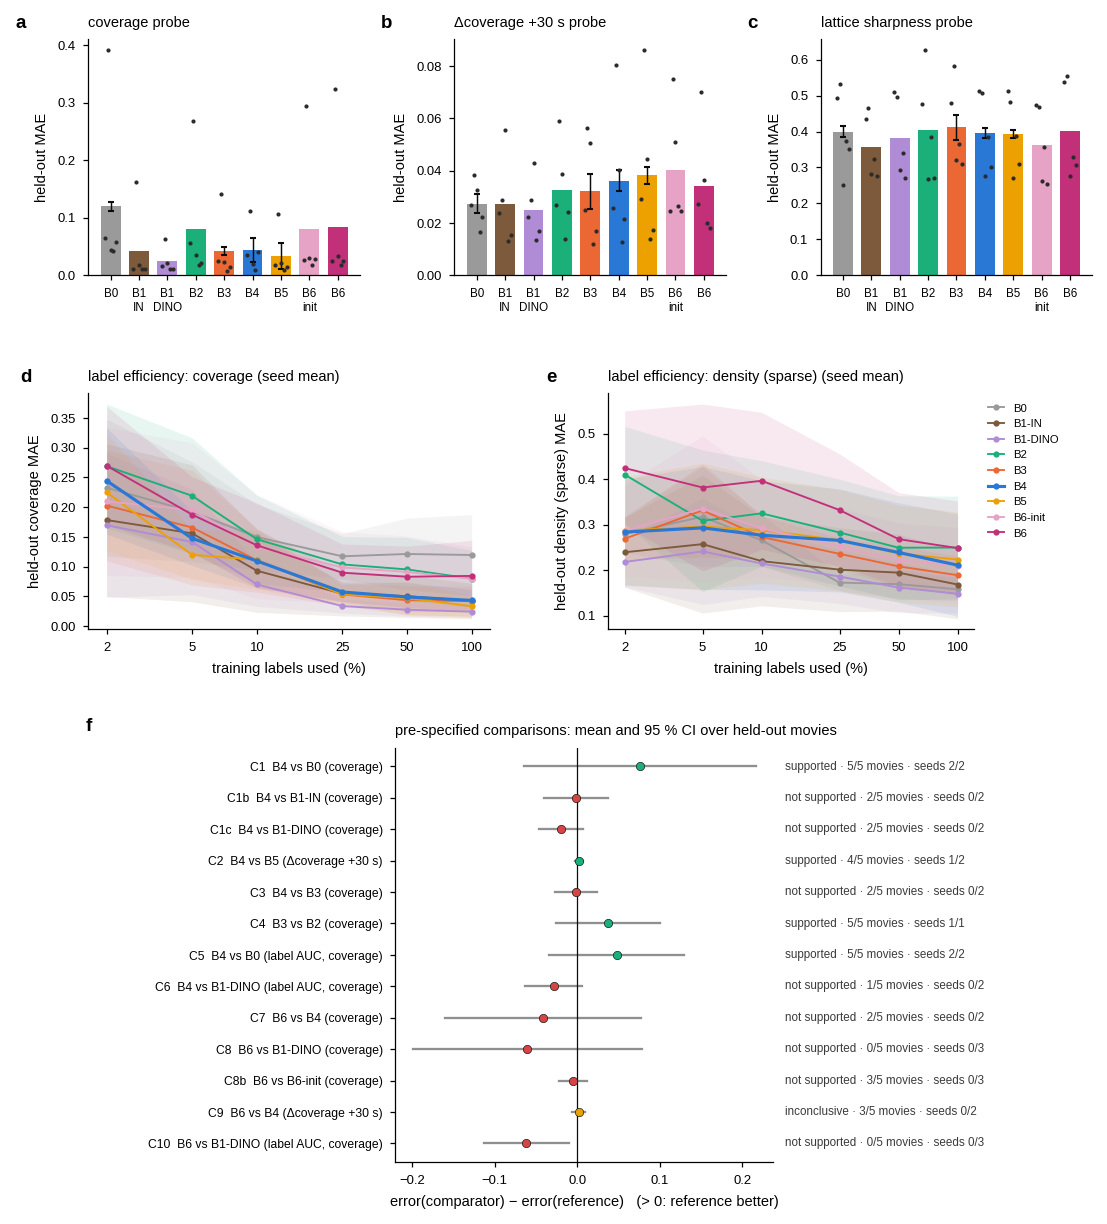

In [11]:
# ---- 10. Figure 6 — representation quality across seeds and against foundation features -------------------------------------------------
def bar_panel(ax, probe, metric='MAE', title=None):
    d = PR[(PR.probe == probe) & (PR.metric == metric)]
    for j, v in enumerate(ENCODERS):
        dv = d[d.variant == v]
        if dv.empty: continue
        fm = dv.groupby('split').value.mean(); fs = dv.groupby('split').value.std().fillna(0)
        ax.bar(j, fm.mean(), color=VCOL[v], width=0.7, zorder=1)
        if v in SSL and dv.seed.nunique() > 1:
            ax.errorbar(j, fm.mean(), yerr=fs.mean(), color='#0b0b0b', lw=0.7, capsize=1.6, zorder=3)
        ax.scatter(np.full(len(fm), j) + np.linspace(-0.2, 0.2, len(fm)), fm.values, s=4, color='#2b2b2b', lw=0, zorder=4)
    ax.set_xticks(range(len(ENCODERS))); ax.set_xticklabels([v.replace('B1-', 'B1\n').replace('B6-', 'B6\n') for v in ENCODERS], fontsize=5.6)
    ax.set_title(title or f'{probe} probe'); ax.set_ylabel('held-out MAE' if metric == 'MAE' else metric)
def mm_axes(fig, FW, FH):
    return lambda x, y, w, h: fig.add_axes([x / FW, 1 - (y + h) / FH, w / FW, h / FH])   # millimetres from the top-left corner
NCL = len(CLAIMS_DEF); FOREST_H = 5.4 * NCL
FW, FH = 183.0, 134.0 + FOREST_H
fig = plt.figure(figsize=(FW * MM, FH * MM)); Ax = mm_axes(fig, FW, FH)
for (pn, lt), x0 in zip([('coverage', 'a'), ('Δcoverage +30 s', 'b'), ('lattice sharpness', 'c')], (12, 74, 136)):
    ax = Ax(x0, 6, 46, 40); bar_panel(ax, pn); panel(ax, lt, x=-0.27)
for (pn, lt), x0, w0 in zip([('coverage', 'd'), ('density (sparse)', 'e')], (12, 100), (68, 62)):
    ax = Ax(x0, 66, w0, 40); d = LE[LE.probe == pn]
    for v in ENCODERS:
        g = d[d.variant == v].groupby(['split', 'seed', 'fraction']).MAE.mean().groupby(['split', 'fraction']).mean().unstack('split')
        if g.empty: continue
        mu_, se = g.mean(1), g.std(1) / np.sqrt(max(1, g.shape[1]))
        ax.plot(g.index, mu_, marker='o', ms=2.0, color=VCOL[v], lw=1.5 if v == 'B4' else 0.9, label=v, zorder=3 if v == 'B4' else 2)
        ax.fill_between(g.index, mu_ - se, mu_ + se, color=VCOL[v], alpha=0.10, lw=0)
    ax.set_xscale('log'); ax.set_xticks(LABEL_FRACTIONS); ax.set_xticklabels([f'{f * 100:g}' for f in LABEL_FRACTIONS]); ax.minorticks_off()
    ax.set_xlabel('training labels used (%)'); ax.set_ylabel(f'held-out {pn} MAE'); ax.set_title(f'label efficiency: {pn} (seed mean)')
    if lt == 'e': ax.legend(fontsize=5.4, ncol=1, loc='upper left', bbox_to_anchor=(1.01, 1.0), handlelength=1.4)
    panel(ax, lt, x=-0.17)
ax = Ax(64, 126, 64, FOREST_H); cl = CL.iloc[::-1].reset_index(drop=True); yy = np.arange(len(cl))
vcol = {'SUPPORTED': '#1baf7a', 'INCONCLUSIVE': '#eda100', 'NOT SUPPORTED': '#d64545', 'NOT AVAILABLE': '#b5b5b5'}
for i, r in cl.iterrows():
    if np.isfinite(r.improvement):
        ax.plot([r.CI95_low, r.CI95_high], [i, i], color='#8f8f8f', lw=1.1)
        ax.scatter(r.improvement, i, s=16, color=vcol[r.verdict], edgecolor='#0b0b0b', lw=0.3, zorder=3)
    ax.text(1.03, i, f"{r.verdict.lower()} · {int(r.won)}/{int(r.n)} movies · seeds {r.seeds_supporting}", transform=ax.get_yaxis_transform(),
            va='center', fontsize=5.6, color='#3a3a3a')
ax.axvline(0, color='#0b0b0b', lw=0.6); ax.set_yticks(yy); ax.set_ylim(-0.6, len(cl) - 0.4)
ax.set_yticklabels([f'{r.id}  {r.reference} vs {r.comparator} ({r.probe.replace("label-efficiency AUC: ", "label AUC, ")})' for _, r in cl.iterrows()], fontsize=5.8)
ax.set_xlabel('error(comparator) − error(reference)   (> 0: reference better)'); ax.set_title('pre-specified comparisons: mean and 95 % CI over held-out movies')
panel(ax, 'f', x=-0.82)
save(fig, 'Figure6_representations_seeds_foundation')

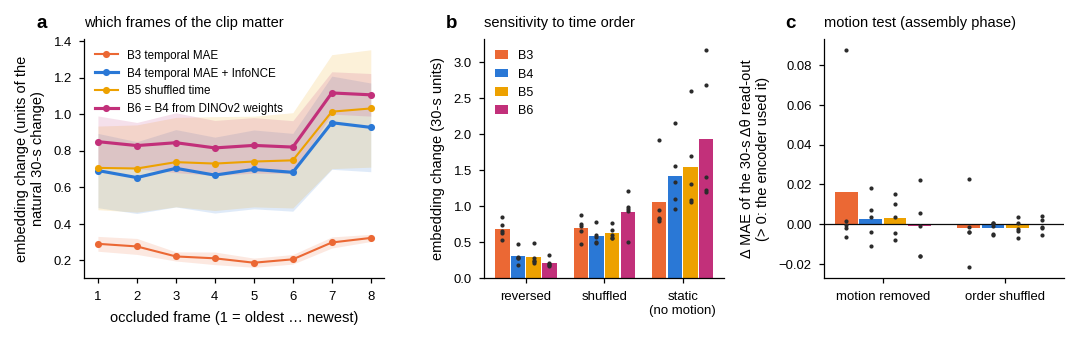

In [12]:
# ---- 11. Figure 7 — temporal mechanism ---------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(W2, 58 * MM), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
ax = axes[0]
for v in TV:
    g = IMP[IMP.variant == v].groupby(['split', 'frame_pos']).emb_change_rel.mean().unstack('split')
    mu_, se = g.mean(1), g.std(1) / np.sqrt(max(1, g.shape[1]))
    ax.plot(g.index + 1, mu_, marker='o', ms=2.4, color=VCOL[v], lw=1.5 if v in ('B4', 'B6') else 1.0, label=VNAME[v])
    ax.fill_between(g.index + 1, mu_ - se, mu_ + se, color=VCOL[v], alpha=0.15, lw=0)
ax.set_xticks(range(1, TFRAMES + 1)); ax.set_xlabel('occluded frame (1 = oldest … newest)')
ax.set_ylabel('embedding change (units of the\nnatural 30-s change)'); ax.set_title('which frames of the clip matter'); ax.legend(loc='upper left', fontsize=5.6); panel(ax, 'a')
ax = axes[1]; pz = ['reversed', 'shuffled', 'static']; w = 0.8 / max(1, len(TV)); off = lambda j: (j - (len(TV) - 1) / 2) * w
for j, v in enumerate(TV):
    g = ORD[ORD.variant == v].groupby(['split', 'perturbation']).emb_change_rel.mean().unstack('perturbation').reindex(columns=pz)
    ax.bar(np.arange(len(pz)) + off(j), g.mean(0), width=w * 0.92, color=VCOL[v], label=v)
    for k, p_ in enumerate(pz):
        ax.scatter(np.full(len(g), k + off(j)), g[p_], s=4, color='#2b2b2b', lw=0, zorder=3)
ax.set_xticks(range(len(pz))); ax.set_xticklabels(['reversed', 'shuffled', 'static\n(no motion)'])
ax.set_ylabel('embedding change (30-s units)'); ax.set_title('sensitivity to time order'); ax.legend(loc='upper left', handlelength=1); panel(ax, 'b')
ax = axes[2]; cols_m = [c for c in ['dMAE_static', 'dMAE_shuffled'] if c in MOT.columns]
for j, v in enumerate(TV):
    g = MOT[MOT.variant == v].groupby('split')[cols_m].mean()
    for k, c in enumerate(cols_m):
        ax.bar(k + off(j), g[c].mean(), width=w * 0.92, color=VCOL[v])
        ax.scatter(np.full(len(g), k + off(j)), g[c], s=4, color='#2b2b2b', lw=0, zorder=3)
ax.axhline(0, color='#0b0b0b', lw=0.6); ax.set_xticks(range(len(cols_m))); ax.set_xticklabels(['motion removed', 'order shuffled'][:len(cols_m)])
ax.set_ylabel('Δ MAE of the 30-s Δθ read-out\n(> 0: the encoder used it)'); ax.set_title('motion test (assembly phase)'); panel(ax, 'c')
fig.tight_layout(); save(fig, 'Figure7_temporal_mechanism')

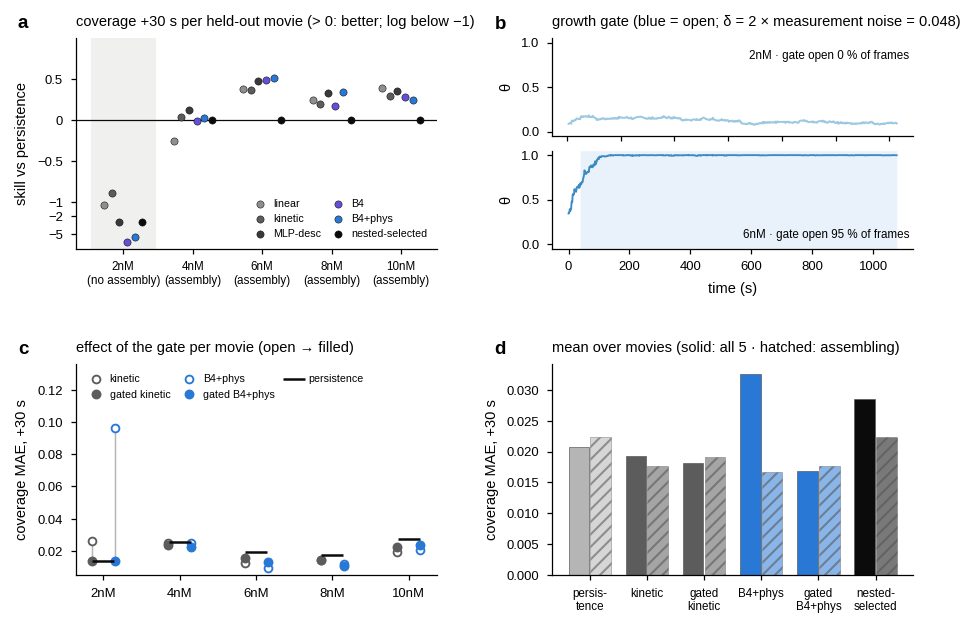

In [13]:
# ---- 12. Figure 8 — forecasting regimes and the growth gate (exploratory) -----------------------------------------------------------------
fig = plt.figure(figsize=(W2, 118 * MM)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], hspace=0.55, wspace=0.32)
ax = fig.add_subplot(gs[0, 0]); cs = [c for c in CONCS if c in prim.columns]; LOW = -1.5
show = [m for m in ['linear', 'kinetic', 'MLP-desc', 'B4', PROPOSED, SELECTED] if m in prim.index]
for i, c in enumerate(cs):
    if REGIME[c] != 'assembling': ax.axvspan(i - 0.45, i + 0.45, color='#f0f0ee', zorder=0)
for k, m in enumerate(show):
    sk = 1 - prim.loc[m, cs].values / prim.loc['persistence', cs].values
    xs = np.arange(len(cs)) + (k - (len(show) - 1) / 2) * 0.11
    ax.scatter(xs, sk, s=12, color=MCOL.get(m, '#3a3a3a'), marker='o', edgecolor='#0b0b0b', lw=0.25, zorder=3, label=m)
skv = 1 - prim.loc[show, cs].values / prim.loc['persistence', cs].values
ax.axhline(0, color='#0b0b0b', lw=0.6); ax.set_yscale('symlog', linthresh=1.0, linscale=1.6)
lo_ = float(np.nanmin(skv)) if np.isfinite(skv).any() else -1.0
yt = [t_ for t_ in [-20, -10, -5, -2, -1, -0.5, 0, 0.5] if t_ >= min(-1, lo_ * 1.3)]
ax.set_yticks(yt); ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}'.replace('-', '\u2212'))); ax.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax.set_ylim(min(-1.2, lo_ * 1.4), 1.0)
ax.set_xticks(range(len(cs))); ax.set_xticklabels([f'{c}\n({"assembly" if REGIME[c] == "assembling" else "no assembly"})' for c in cs], fontsize=5.6)
ax.set_ylabel('skill vs persistence'); ax.set_title(f'coverage +{PH:.0f} s per held-out movie (> 0: better; log below −1)')
ax.legend(fontsize=5.1, ncol=2, loc='lower right', handletextpad=0.2, columnspacing=0.6); panel(ax, 'a')
sub = gs[0, 1].subgridspec(2, 1, hspace=0.15)
ex_m = [c for c in CONCS if REGIME[c] != 'assembling'][:1] + [c for c in ['6nM', '4nM', '8nM', '10nM'] if c in CONCS and REGIME[c] == 'assembling'][:1]
for k, c in enumerate(ex_m):
    a = fig.add_subplot(sub[k]); rr = np.where(A_.conc.values == c)[0]
    a.plot(T_ABS[rr], Ycov[rr], color=CCOL[c], lw=0.9)
    gt = GATE[rr]; a.fill_between(T_ABS[rr], -0.05, 1.05, where=gt, color='#2a78d6', alpha=0.10, lw=0, step='post')
    hi_end = np.nanmean(Ycov[rr][-max(1, len(rr) // 4):]) > 0.5
    a.set_ylim(-0.05, 1.05); a.set_ylabel('θ'); a.text(0.99, 0.08 if hi_end else 0.88, f'{c} · gate open {gt.mean() * 100:.0f} % of frames', transform=a.transAxes,
                                                    ha='right', va='bottom' if hi_end else 'top', fontsize=5.6)
    if k == 0: a.set_title(f'growth gate (blue = open; δ = 2 × measurement noise = {DELTA:.3f})'); panel(a, 'b', y=1.06)
    if k < len(ex_m) - 1: a.set_xticklabels([])
    else: a.set_xlabel('time (s)')
ax = fig.add_subplot(gs[1, 0])
for k, b_ in enumerate([b for b in ['kinetic', PROPOSED] if b in prim.index and f'gated {b}' in prim.index]):
    xs = np.arange(len(cs)) + (k - 0.5) * 0.3
    ax.scatter(xs, prim.loc[b_, cs], s=14, facecolor='white', edgecolor=MCOL.get(b_, '#3a3a3a'), lw=0.9, zorder=3, label=f'{b_}')
    ax.scatter(xs, prim.loc[f'gated {b_}', cs], s=14, color=MCOL.get(b_, '#3a3a3a'), zorder=4, label=f'gated {b_}')
    for x_, a0, a1 in zip(xs, prim.loc[b_, cs], prim.loc[f'gated {b_}', cs]): ax.plot([x_, x_], [a0, a1], color='#b5b5b5', lw=0.7, zorder=2)
ax.scatter(np.arange(len(cs)), prim.loc['persistence', cs], marker='_', s=120, color='#0b0b0b', lw=1.2, zorder=5, label='persistence')
ax.set_xticks(range(len(cs))); ax.set_xticklabels(cs); ax.set_ylabel(f'coverage MAE, +{PH:.0f} s'); ax.set_title('effect of the gate per movie (open → filled)')
ax.set_ylim(top=ax.get_ylim()[1] * 1.35); ax.legend(fontsize=5.1, ncol=3, loc='upper left', handletextpad=0.3, columnspacing=0.8); panel(ax, 'c')
ax = fig.add_subplot(gs[1, 1]); bars = [m for m in ['persistence', 'kinetic', 'gated kinetic', PROPOSED, f'gated {PROPOSED}', SELECTED] if m in prim.index]
w = 0.38
for j, (colname, hatch) in enumerate([('mean (all movies)', None), ('mean (assembling)', '////')]):
    ax.bar(np.arange(len(bars)) + (j - 0.5) * w, prim.loc[bars, colname], width=w * 0.95,
           color=[MCOL.get(m.replace('gated ', ''), '#3a3a3a') for m in bars], alpha=1.0 if j == 0 else 0.55, hatch=hatch, edgecolor='#52514e', lw=0.3)
ax.set_xticks(range(len(bars))); ax.set_xticklabels([m.replace('gated ', 'gated\n').replace('nested-selected', 'nested-\nselected').replace('persistence', 'persis-\ntence') for m in bars], fontsize=5.6)
ax.set_ylabel(f'coverage MAE, +{PH:.0f} s'); ax.set_title('mean over movies (solid: all 5 · hatched: assembling)')
panel(ax, 'd')
save(fig, 'Figure8_forecasting_regimes')

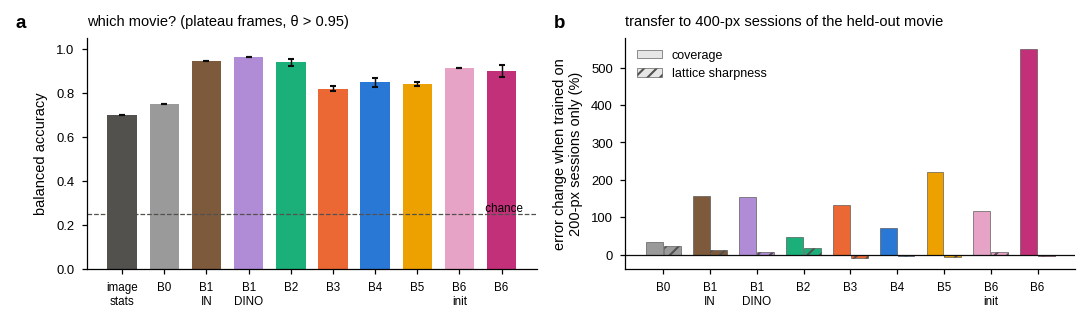

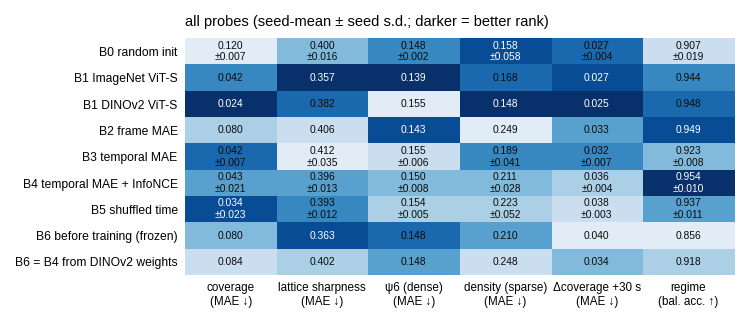

In [14]:
# ---- 13. Supplementary figures: nuisance probe, acquisition transfer, all probes x encoders ----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(W2, 55 * MM))
ax = axes[0]
if len(NUIS_SUM):
    labs_ = list(NUIS_SUM.index)
    ax.bar(range(len(labs_)), NUIS_SUM['mean'], color=[VCOL.get(v, '#52514e') for v in labs_], width=0.7)
    ax.errorbar(range(len(labs_)), NUIS_SUM['mean'], yerr=NUIS_SUM['std'].fillna(0), fmt='none', ecolor='#0b0b0b', lw=0.7, capsize=1.5)
    ax.axhline(float(NUIS_SUM.chance.iloc[0]), color='#52514e', ls='--', lw=0.6); ax.text(len(labs_) - 0.5, float(NUIS_SUM.chance.iloc[0]), ' chance', fontsize=5.6, va='bottom', ha='right')
    ax.set_xticks(range(len(labs_))); ax.set_xticklabels([l.replace('image statistics', 'image\nstats').replace('B1-', 'B1\n').replace('B6-', 'B6\n') for l in labs_], fontsize=5.6)
    ax.set_ylim(0, 1.05); ax.set_ylabel('balanced accuracy'); ax.set_title('which movie? (plateau frames, θ > 0.95)')
panel(ax, 'a')
ax = axes[1]
if len(ACQ):
    for k, (pn, hatch) in enumerate([('coverage', None), ('lattice sharpness', '////')]):
        dd = ACQ[ACQ.probe == pn].groupby(['variant', 'mode', 'split']).MAE.mean().groupby(['variant', 'mode']).mean().unstack('mode').reindex(ENCODERS)
        if 'train 200 px only' not in dd or 'train all frames' not in dd: continue
        gap = (dd['train 200 px only'] - dd['train all frames']) / dd['train all frames'] * 100
        ax.bar(np.arange(len(ENCODERS)) + (k - 0.5) * 0.38, gap.values, width=0.36, color=[VCOL[v] for v in ENCODERS], hatch=hatch, edgecolor='#52514e', lw=0.3, label=pn)
    ax.axhline(0, color='#0b0b0b', lw=0.6); ax.set_xticks(range(len(ENCODERS))); ax.set_xticklabels([v.replace('B1-', 'B1\n').replace('B6-', 'B6\n') for v in ENCODERS], fontsize=5.6)
    ax.set_ylabel('error change when trained on\n200-px sessions only (%)'); ax.set_title('transfer to 400-px sessions of the held-out movie')
    ax.legend(handles=[Patch(fc='#e6e6e6', ec='#52514e', lw=0.3, label='coverage'), Patch(fc='#e6e6e6', ec='#52514e', lw=0.3, hatch='////', label='lattice sharpness')], loc='upper left')
panel(ax, 'b')
fig.tight_layout(); save(fig, 'FigS7_1_nuisance_and_acquisition', SUPF)
hm = SUMM.pivot_table(index='variant', columns='probe', values='mean').reindex(index=ENCODERS)
hm = hm[[p_ for p_ in PROBES if p_ in hm.columns]]
fig, ax = plt.subplots(figsize=(W15, 52 * MM))
rk = hm.rank(axis=0, ascending=True)
if 'regime' in hm.columns: rk['regime'] = hm['regime'].rank(ascending=False)
im = ax.imshow(rk.values, cmap='Blues_r', aspect='auto', vmin=1, vmax=len(ENCODERS) + 1)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v_ = hm.values[i, j]; s_ = SUMM[(SUMM.variant == hm.index[i]) & (SUMM.probe == hm.columns[j])].seed_sd
        txt = '–' if not np.isfinite(v_) else (f'{v_:.3f}' + (f'\n±{float(s_.iloc[0]):.3f}' if len(s_) and np.isfinite(s_.iloc[0]) and s_.iloc[0] > 0 else ''))
        ax.text(j, i, txt, ha='center', va='center', fontsize=4.9, color='white' if rk.values[i, j] <= 2 else '#0b0b0b')
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels([c + ('\n(bal. acc. ↑)' if c == 'regime' else '\n(MAE ↓)') for c in hm.columns], fontsize=5.6)
ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels([VNAME[v] for v in hm.index], fontsize=5.8); ax.tick_params(length=0)
for sp_ in ax.spines.values(): sp_.set_visible(False)
ax.set_title('all probes (seed-mean ± seed s.d.; darker = better rank)')
save(fig, 'FigS7_2_all_probes_seeds', SUPF)

In [15]:
# ---- 14. Tables T10–T13 (CSV + LaTeX booktabs + one Excel workbook) ------------------------------------------------------------------------
def to_latex_booktabs(df, caption, label, fmt='{:.4g}'):
    def cell(v):
        if isinstance(v, (float, np.floating)):
            return '--' if not np.isfinite(v) else fmt.format(v)
        return str(v).replace('_', r'\_').replace('%', r'\%').replace('&', r'\&').replace('±', r'$\pm$').replace('θ', r'$\theta$').replace('ψ', r'$\psi$').replace('Δ', r'$\Delta$')
    d = df.reset_index()
    cols = [cell(c) if not isinstance(c, tuple) else ' '.join(cell(x) for x in c) for c in d.columns]
    lines = [r'\begin{table}[ht]', r'\centering', r'\small', f'\\caption{{{cell(caption)}}}', f'\\label{{tab:{label}}}',
             r'\begin{tabular}{' + 'l' + 'r' * (len(cols) - 1) + '}', r'\toprule', ' & '.join(cols) + r' \\', r'\midrule']
    lines += [' & '.join(cell(v) for v in r.values) + r' \\' for _, r in d.iterrows()]
    return '\n'.join(lines + [r'\bottomrule', r'\end{tabular}', r'\end{table}'])
TABLES = {}
def save_table(df, name, caption):
    df.to_csv(os.path.join(TAB, f'{name}.csv')); open(os.path.join(TAB, f'{name}.tex'), 'w').write(to_latex_booktabs(df, caption, name))
    TABLES[name] = (df, caption)
T10 = SUMM.assign(cell=[f'{m:.4f} ± {s:.4f}' if np.isfinite(s) else f'{m:.4f}' for m, s in zip(SUMM['mean'], SUMM.seed_sd)]) \
          .pivot(index='variant', columns='probe', values='cell').reindex(ENCODERS)
save_table(T10, 'T10_probes_seeds', f'Frozen-encoder linear probes on held-out movies: mean over {len(LOCO)} LOCO folds of the seed-mean ± seed s.d. '
           f'({len(SEEDS)} pretraining seeds; B1 foundation encoders are deterministic). Regime = balanced accuracy, all others MAE.')
save_table(CL.set_index('id')[['claim', 'MAE_reference', 'MAE_comparator', 'improvement', 'CI95_low', 'CI95_high', 'cohens_dz', 'won', 'n', 'p', 'q_BH',
                                'verdict', 'seeds_supporting']], 'T11_claims_confirmatory',
           'Pre-specified representation claims: paired over held-out movies on seed-averaged values; exact sign-flip p; BH q over the claims; '
           'seeds_supporting = claim verdict recomputed with each pretraining seed alone.')
save_table(prim, 'T12_forecast_regimes', f'Coverage MAE +{PH:.0f} s per held-out movie (all anchors). Rows "gated" are an exploratory, causal growth gate '
           f'(persistence until the 30-s running median rises {DELTA:.3f} above the first 30 s; δ = 2 × trace–retrace noise).')
if len(NEWBEST):
    save_table(NEWBEST.set_index(['probe', 'encoder']), 'T14_new_vs_previous_best',
               'New encoders (foundation baselines, B6) against the best Portion 3-6 encoder of each probe; paired over held-out movies.')
if len(NUIS_SUM):
    save_table(NUIS_SUM.rename(columns={'mean': 'balanced acc.', 'std': 's.d. over folds', 'count': 'encoders'}), 'T13a_nuisance_movie_identity',
               'Movie identity decoded from plateau frames (θ > 0.95) with time-blocked cross-validation; high accuracy = acquisition/session signature.')
if len(ACQ_SUM):
    save_table(ACQ_SUM, 'T13b_acquisition_transfer',
               "Probe MAE on the held-out movie's 400-px session frames when trained on 200-px frames only vs on all frames.")
try:
    with pd.ExcelWriter(os.path.join(TAB, 'portion7_tables.xlsx')) as xw:
        for name, (df, cap) in TABLES.items():
            df.to_excel(xw, sheet_name=name[:31])
except Exception as e:
    print('Excel export skipped:', e)
print('tables:', sorted(os.listdir(TAB)))

tables: ['T10_probes_seeds.csv', 'T10_probes_seeds.tex', 'T11_claims_confirmatory.csv', 'T11_claims_confirmatory.tex', 'T12_forecast_regimes.csv', 'T12_forecast_regimes.tex', 'T13a_nuisance_movie_identity.csv', 'T13a_nuisance_movie_identity.tex', 'T13b_acquisition_transfer.csv', 'T13b_acquisition_transfer.tex', 'T14_new_vs_previous_best.csv', 'T14_new_vs_previous_best.tex', 'portion7_tables.xlsx']


In [16]:
# ---- 15. Results summary, figure legends, checks and manifest ---------------------------------------------------------------------------------
def fmt(x, d=4):
    return '–' if x is None or not np.isfinite(x) else f'{x:.{d}f}'
S = [f'# Portion 7 results (auto-generated {datetime.now().isoformat(timespec="seconds")})', '',
     f'- Seeds: {len(SEEDS)} pretraining seeds per encoder ({SEEDS}); foundation baselines: {", ".join(FOUND) or "none"}.',
     f'- Reproduction: Portion 3 probes {"reproduced" if REPRO_P3["ok"] else "NOT reproduced"} (max |Δ| {fmt(REPRO_P3["max_abs_diff_MAE"], 6)}); '
     f'Portion 5 label efficiency {"reproduced" if REPRO_P5["ok"] else "NOT reproduced"}; Portion 4 targets {"reproduced" if REPRO_P4["ok"] else "NOT reproduced"}.', '',
     '## Pre-specified representation claims (seed-averaged, 5 held-out movies)']
for _, r in CL.iterrows():
    S.append(f'- {r.id} {r.claim}: Δ = {fmt(r.improvement)} [{fmt(r.CI95_low)}, {fmt(r.CI95_high)}], {int(r.won)}/{int(r.n)} movies, p = {fmt(r.p, 3)}, '
             f'q = {fmt(r.q_BH, 3)} → **{r.verdict}** (seeds supporting {r.seeds_supporting}).')
if len(NEWBEST):
    S += ['', '## New encoders vs the best encoder of Portions 3–6 (per probe)']
    for _, r in NEWBEST.iterrows():
        S.append(f'- {r.probe}: {r.encoder} {fmt(r.MAE_encoder)} vs best previous {r.previous_best} {fmt(r.MAE_previous_best)} '
                 f'({r.change_pct:+.1f} %, better in {r.movies_better} movies, p = {fmt(r.p, 3)}) → **{r.verdict}**.')
S += ['', '## Temporal mechanism (Portion 7A)']
for _, r in TEMPS.iterrows():
    S.append(f'- {r.variant}: order change reversed {fmt(r.get("order_change_reversed", np.nan), 3)}, shuffled {fmt(r.get("order_change_shuffled", np.nan), 3)}, '
             f'static {fmt(r.get("order_change_static", np.nan), 3)} (30-s units); motion test ΔMAE static {fmt(r.get("dMAE_static", np.nan))} '
             f'({r.get("dMAE_static_folds_positive", "–")} folds > 0), shuffled {fmt(r.get("dMAE_shuffled", np.nan))}.')
S += ['', f'## Forecasting regimes (exploratory) — coverage +{PH:.0f} s', f'- Regimes from the data: {REGIME}.']
for m in [x for x in ['persistence', 'kinetic', PROPOSED, SELECTED, 'gated kinetic', f'gated {PROPOSED}'] if x in prim.index]:
    S.append(f'- {m}: mean MAE all movies {fmt(prim.loc[m, "mean (all movies)"])}, assembling movies {fmt(prim.loc[m, "mean (assembling)"])}.')
if len(NUIS_SUM):
    S += ['', '## Nuisance probe', '- movie identity (balanced accuracy, chance ' + fmt(float(NUIS_SUM.chance.iloc[0]), 2) + '): ' +
          ', '.join(f'{i} {fmt(r["mean"], 2)}' for i, r in NUIS_SUM.iterrows()) + '.']
S += ['', f'Decision rule: SUPPORTED = better on average and in ≥ {int(SUPPORT_MIN_FRAC * 100)} % of held-out movies. Minimum exact p with 5 movies = 0.0625.']
if QUICK: S += ['', '**WARNING: Portion 3 ran in QUICK mode — these numbers only prove the pipeline runs.**']
open(os.path.join(TXT, 'results_summary_portion7.md'), 'w').write('\n'.join(S)); print('\n'.join(S))
legends = f"""# Figure legends (draft)

**Figure 6 | Representation quality across pretraining seeds and against foundation features.** (a–c) Frozen-encoder linear probes on
held-out movies (bars: mean over {len(LOCO)} leave-one-concentration-out folds of the seed-mean; dots: folds; error bars: mean across-seed s.d.,
{len(SEEDS)} seeds). B1: frozen ImageNet ViT-S/16 and DINOv2 ViT-S/14 features of the same 960-nm crop; B6: the B4 clip model trained with the
Portion 3 recipe but started from {B6_INIT} weights (one run per fold). (d) Held-out coverage error versus the
fraction of training labels; (e) same for the sparse-regime density (whole 30-s blocks; mean ± s.e. over movies of the seed-mean). (f) Pre-specified comparisons: mean improvement and
95 % CI over held-out movies; text = verdict, movies improved and the number of seeds for which the claim holds on its own.

**Figure 7 | Temporal mechanism of the clip encoders.** (a) Embedding change when one frame of the 8-frame clip is replaced by the clip mean,
in units of the encoder's natural 30-s embedding change (standardised Euclidean distance). (b) Embedding change for reversed, shuffled and static (last frame repeated) clips.
(c) Change in error of the 30-s coverage-change read-out when motion is removed or order destroyed (assembly-phase frames; > 0 = information used).
Dots: folds (mean over seeds).

**Figure 8 | Forecasting regimes (exploratory).** (a) Skill versus persistence for coverage +{PH:.0f} s on each held-out movie; grey column =
movie without assembly. (b) Causal growth gate on a non-assembling and an assembling movie (open once the 30-s running median of coverage rises
δ = {DELTA:.3f}, twice the trace–retrace measurement noise, above the first 30 s). (c) Per-movie error of the kinetic and proposed forecasts
without (open) and with (filled) the gate; bars mark persistence. (d) Mean error over all 5 and over the assembling movies. The gate was
defined after Portion 4 and is reported as an exploratory analysis.
"""
open(os.path.join(TXT, 'figure_legends_portion7.md'), 'w').write(legends)
checks = [('Seed 0 reproduces Portion 3 probes', 'PASS' if REPRO_P3['ok'] else 'CHECK', str(REPRO_P3)),
          ('Seed 0 reproduces Portion 5 label efficiency', 'PASS' if REPRO_P5['ok'] else 'CHECK', str(REPRO_P5)),
          ('Rebuilt targets reproduce Portion 4 v2 metrics', 'PASS' if REPRO_P4['ok'] else 'CHECK', str(REPRO_P4)),
          ('No encoder saw its held-out movie', 'PASS', 'asserted for every embedding file loaded'),
          ('Seeds available for every SSL encoder', 'PASS' if not missing_enc else 'CHECK', f'{len(SEEDS)} seeds; missing {missing_enc}'),
          ('Foundation baselines available', 'PASS' if {'B1-IN', 'B1-DINO'} <= set(FOUND) else 'CHECK', ', '.join(FOUND) or 'none'),
          ('B6 (foundation-initialised) available', 'PASS' if HAS_B6 else 'CHECK', f'init {B6_INIT}' if HAS_B6 else 'not trained yet: re-run Portion 7A')]
CHK = pd.DataFrame(checks, columns=['check', 'status', 'detail']); CHK.to_csv(os.path.join(OUT, 'checks_portion7B.csv'), index=False); display(CHK)
man = {}
for f in sorted(glob.glob(os.path.join(OUT, '*.csv')) + glob.glob(os.path.join(TAB, '*.csv'))):
    man[os.path.relpath(f, OUT)] = hashlib.md5(open(f, 'rb').read()).hexdigest()
json.dump(dict(created=datetime.now().isoformat(timespec='seconds'), numpy=np.__version__, pandas=pd.__version__, seeds=SEEDS, encoders=ENCODERS,
               label_repeats=LABEL_REPEATS, delta_gate=DELTA, regimes=REGIME, decision_rule=f'mean > 0 and >= {SUPPORT_MIN_FRAC:.0%} of movies', md5=man),
          open(os.path.join(TXT, 'manifest_portion7.json'), 'w'), indent=1)
zf = os.path.join(OUT, 'portion7_package.zip')
with zipfile.ZipFile(zf, 'w', zipfile.ZIP_DEFLATED) as z:
    for d in [MAINF, SUPF, TAB, TXT, os.path.join(OUT, 'figures')]:
        for f in sorted(glob.glob(os.path.join(d, '*'))):
            z.write(f, os.path.relpath(f, OUT))
print(f'package: {zf} ({os.path.getsize(zf) / 1e6:.1f} MB)')

# Portion 7 results (auto-generated 2026-10-16T18:41:30)

- Seeds: 3 pretraining seeds per encoder ([0, 1, 2]); foundation baselines: B1-IN, B1-DINO, B6-init.
- Reproduction: Portion 3 probes NOT reproduced (max |Δ| 0.000458); Portion 5 label efficiency NOT reproduced; Portion 4 targets reproduced.

## Pre-specified representation claims (seed-averaged, 5 held-out movies)
- C1 Temporal SSL (B4) reads coverage better than a random encoder: Δ = 0.0763 [-0.0644, 0.2171], 5/5 movies, p = 0.062, q = 0.163 → **SUPPORTED** (seeds supporting 2/2).
- C1b B4 reads coverage better than frozen ImageNet ViT-S features: Δ = -0.0011 [-0.0397, 0.0376], 2/5 movies, p = 0.875, q = 0.938 → **NOT SUPPORTED** (seeds supporting 0/2).
- C1c B4 reads coverage better than frozen DINOv2 ViT-S features: Δ = -0.0190 [-0.0457, 0.0076], 2/5 movies, p = 0.250, q = 0.406 → **NOT SUPPORTED** (seeds supporting 0/2).
- C2 True time order helps the dynamics read-out (B4 vs shuffled-time B5): Δ = 0.0021 [-0.0027, 0.0069],

,check,status,detail
0,Seed 0 reproduces Portion 3 probes,CHECK,"{'n': 145, 'max_abs_diff_MAE': 0.0004578164370..."
1,Seed 0 reproduces Portion 5 label efficiency,CHECK,"{'n': 1950, 'max_abs_diff': 0.0026605124364145..."
2,Rebuilt targets reproduce Portion 4 v2 metrics,PASS,"{'n': 10, 'max_abs_diff': 9.194034422677078e-1..."
3,No encoder saw its held-out movie,PASS,asserted for every embedding file loaded
4,Seeds available for every SSL encoder,CHECK,"3 seeds; missing [('B2', 1), ('B2', 2), ('B3',..."
5,Foundation baselines available,PASS,"B1-IN, B1-DINO, B6-init"
6,B6 (foundation-initialised) available,PASS,init B1-DINO


package: /content/drive/MyDrive/Koushik-experiment/portion7_outputs/portion7_package.zip (8.3 MB)


## What you have now (`portion7_outputs/`)
| File | Use |
|---|---|
| `main_figures/Figure6–8` | seeds + foundation baselines, temporal mechanism, forecasting regimes (PDF, 600-dpi PNG, TIFF) |
| `supplementary_figures/FigS7_*` | nuisance probe, acquisition transfer, all probes × encoders |
| `tables/T10–T13` (+ `.tex`, `portion7_tables.xlsx`) | journal tables |
| `claims_confirmatory.csv`, `probes_all_seeds.csv`, `label_efficiency_all_seeds.csv`, `forecast_regimes_*.csv` | the numbers behind every figure |
| `text/results_summary_portion7.md`, `figure_legends_portion7.md`, `manifest_portion7.json` | draft text and MD5 manifest |

**Reading the verdicts:** a claim is SUPPORTED only if it holds on average **and** in ≥ 4 of 5 held-out movies; "seeds supporting" tells you
whether it also holds for each pretraining seed separately. The growth gate (Figure 8) is exploratory: report it as a post-hoc analysis.